# Límites de detección: auditoría del operador FRP publicado
Componente de investigación para la corrección física futura. No modifica las series de la
demo ni estima cuántos incendios faltan. Implementación independiente de las ecuaciones 5–7
de Sofiev y Kouznetsov (2026), con constantes de las tablas publicadas y atribución CC BY 4.0.
No se incorpora código del repositorio FRP_OOp.

In [1]:
from pathlib import Path
import os,sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path(os.environ.get('FIRMS_ARTIFACTS_DIR','outputs')).resolve()
OUT=ROOT/'26_operador_observacion'
sys.path[:0]=[str(OUT),str(Path.cwd()/'research/frp_operator'),
              str(Path.cwd().parent/'research/frp_operator')]
from frp_operator import parameters,response_weight,forward_frp,COEFFICIENTS
audit=json.loads((OUT/'operator_audit.json').read_text())
summary=pd.read_csv(OUT/'development_detection_limit_diagnostics.csv')
display(pd.DataFrame([{'instrument':s,'daynight':dn,'slope_mw_km2':v[0],
    'intercept_mw':v[1],'rate_shift':v[2],'rate_scale':v[3],'cutoff':v[4]}
    for (s,dn),v in COEFFICIENTS.items()]))
print('Fuente: https://gmd.copernicus.org/articles/19/10123/2026/')

,instrument,daynight,slope_mw_km2,intercept_mw,rate_shift,rate_scale,cutoff
0,MODIS,D,4.44,0.52,0.07,1.26,0.045
1,MODIS,N,4.43,1.01,0.11,1.06,0.045
2,VIIRS,D,6.17,1.44,0.61,0.21,0.050
3,VIIRS,N,1.38,0.35,2.12,1.02,0.050


Fuente: https://gmd.copernicus.org/articles/19/10123/2026/


## 1. Qué calcula
Para un área de píxel A, el punto medio de la curva es D = pendiente × A + intercepto.
La pendiente logística usa r = r0 + r1/A. La ecuación 6 contiene A0, sin valor en las tablas:
aquí declaramos A0 = 0 como supuesto pendiente de confirmación.
La respuesta se obtiene desplazando y reescalando la sigmoide según la ecuación 7.
Entrada: FRP hipotética de un píxel bajo recuperación válida. Salida: FRP observada esperada
según ese operador. No es una transformación inversa de conteos FIRMS.
Un píxel sin recuperación válida permanece NaN en nuestro contrato de datos.

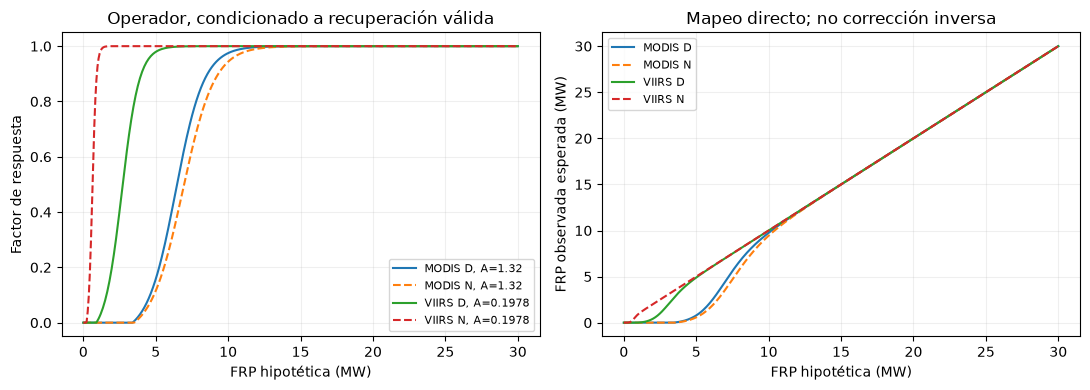

In [2]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
power=np.linspace(0,30,400)
for sensor,area in [('MODIS',1.32),('VIIRS',.1978)]:
    for dn,style in [('D','-'),('N','--')]:
        axes[0].plot(power,response_weight(power,area,sensor,dn),style,label=f'{sensor} {dn}, A={area}')
        axes[1].plot(power,forward_frp(power,area,sensor,dn),style,label=f'{sensor} {dn}')
axes[0].set(xlabel='FRP hipotética (MW)',ylabel='Factor de respuesta',title='Operador, condicionado a recuperación válida')
axes[1].set(xlabel='FRP hipotética (MW)',ylabel='FRP observada esperada (MW)',title='Mapeo directo; no corrección inversa')
for ax in axes:ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();plt.show()

## 2. Diferencia numérica pendiente de resolver
Evaluar las tablas a un área MODIS de 1 km² produce 4,96 MW de día y 5,44 MW de noche.
El resumen del artículo menciona 3,7 MW nocturnos. Esta comparación indica una discrepancia
entre la evaluación literal de la tabla y el resumen; no demuestra por sí sola cuál cambiar.
Conservamos los valores publicados y registramos la diferencia. La integración física exige
confirmar el contexto y los parámetros adecuados, además de validarlos en Perú.

In [3]:
display(pd.DataFrame.from_dict(audit['paper_text_consistency']['table_evaluations'],orient='index'))
display(pd.Series({'texto nocturno MODIS, MW':3.7,'tabla nocturna MODIS con A=1 km², MW':5.44,
                   'discrepancia resuelta':False,'habilitado en producción':False}))

,assumed_pixel_area_km2,table_midpoint_mw,rate_inverse_mw,cutoff
MODIS_D,1.000000,4.960000,1.330000,0.045
MODIS_N,1.000000,5.440000,1.170000,0.045
VIIRS_D,0.140625,2.307656,2.103333,0.050
VIIRS_N,0.140625,0.544062,9.373333,0.050


texto nocturno MODIS, MW                  3.7
tabla nocturna MODIS con A=1 km², MW     5.44
discrepancia resuelta                   False
habilitado en producción                False
dtype: object

## 3. Diagnóstico sobre detecciones peruanas de desarrollo
Solo 2013–2021, SP type=0 dentro del límite MINAM. El área usa scan × track redondeados
del CSV: es un proxy, no una reconstrucción óptica exacta del píxel.
La proporción bajo D cuenta detecciones YA REPORTADAS con FRP inferior al punto medio de
tabla. No mide la proporción de incendios omitidos. Aplicar 1/respuesta a esos positivos
ignoraría los incendios no observados, su distribución FRP y la cobertura.

,platform,daynight,reported_detections,frp_median_mw,area_median_km2,table_midpoint_median_mw,reported_share_below_table_midpoint,reported_zero_frp_share,median_response_factor_on_reported_frp
0,Aqua,D,103136,16.80,1.3200,6.38080,0.05217,0.00001,0.99939
1,Aqua,N,1345,13.20,1.3200,6.85760,0.16580,0.00000,0.98992
2,NOAA-20,D,271193,6.27,0.1978,2.66043,0.09512,0.00000,0.99608
3,NOAA-20,N,21120,1.51,0.1890,0.61082,0.06899,0.00005,0.99818
4,Suomi-NPP,D,582830,6.19,0.1978,2.66043,0.09690,0.00000,0.99571
5,Suomi-NPP,N,43174,1.55,0.1960,0.62048,0.06641,0.00000,0.99826
6,Terra,D,18659,14.80,1.3200,6.38080,0.06801,0.00000,0.99652
7,Terra,N,3344,11.90,1.3200,6.85760,0.22279,0.00060,0.97467


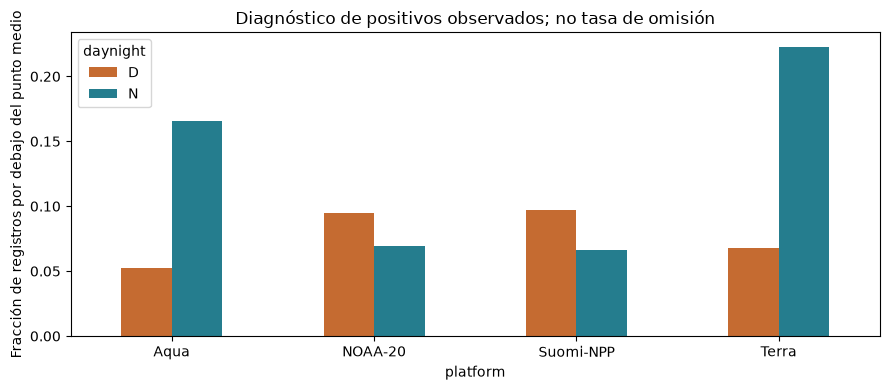

Puntos de desarrollo auditados: 1044801


In [4]:
display(summary.round(5))
plot=summary.pivot(index='platform',columns='daynight',values='reported_share_below_table_midpoint')
ax=plot.plot.bar(figsize=(9,4),color=['#c56b31','#257d8e'])
ax.set(ylabel='Fracción de registros por debajo del punto medio',title='Diagnóstico de positivos observados; no tasa de omisión')
ax.tick_params(axis='x',rotation=0);plt.tight_layout();plt.show()
print('Puntos de desarrollo auditados:',audit['reported_points_audited'])

## 4. Condiciones para usarlo en la armonización completa
Deben validarse máscaras, soporte espacial y oportunidades observadas; separar día/noche;
resolver los supuestos de parámetros; evaluar el mapeo entre plataformas y su incertidumbre.
El operador FRP y el modelo de conteos necesitan una conexión observacional identificada:
el primero no recupera automáticamente los segundos.
Fuente: https://doi.org/10.5194/gmd-19-10123-2026, tablas 1–2 y ecuaciones 5–7.

In [5]:
assert not audit['national_series_changed']
assert not audit['inverse_probability_count_correction_performed']
assert not audit['final_test_2024_2025_used']
assert audit['status']=='research_diagnostic_not_production'
print('La demo permanece intacta. Este componente aún no certifica una corrección física.')

La demo permanece intacta. Este componente aún no certifica una corrección física.
